In [1]:
from load_basics import *
from nbodykit.source.catalog import BigFileCatalog
from nbodykit.lab import ArrayCatalog, FFTPower
import h5py, glob
# from astrid_utils import *
from astropy.cosmology import Planck15 as cosmo
from astropy import units


### functions

In [2]:
def gen_mesh_g4(flist, snap, Lbox = 400, Nmesh = 128, comp = False):
    asnap = alist[snap]
    sdir = flist[snap]
    

    hf = h5py.File(sdir)
    pos = hf["PartType1/Coordinates"][:]
    vel = hf["PartType1/Velocities"][:]
    cat = ArrayCatalog({'Position' : pos, 'Velocity' : vel}, BoxSize=[Lbox, Lbox, Lbox])
    cat["Vx"] = vel[:, 0] * np.sqrt(asnap) # to peculiar velocity in km/s
    cat["Vy"] = vel[:, 1] * np.sqrt(asnap)
    cat["Vz"] = vel[:, 2] * np.sqrt(asnap)
    mesh_rho = cat.to_mesh(compensated=comp, resampler='tsc',Nmesh=Nmesh,position='Position')
    mesh_vx = cat.to_mesh(compensated=comp, resampler='tsc', position='Position', value='Vx', Nmesh=Nmesh)
    mesh_vy = cat.to_mesh(compensated=comp, resampler='tsc', position='Position', value='Vy', Nmesh=Nmesh)
    mesh_vz = cat.to_mesh(compensated=comp, resampler='tsc', position='Position', value='Vz', Nmesh=Nmesh)
    return mesh_rho, mesh_vx, mesh_vy, mesh_vz

def downsize(one_plus_delta, factor):
    """
    Downsize the mesh by a factor of `factor`.
    """
    if factor == 1:
        return one_plus_delta
    elif factor < 1:
        raise ValueError("Downsize factor must be >= 1")
    
    new_shape = (one_plus_delta.shape[0] // factor, 
                 one_plus_delta.shape[1] // factor, 
                 one_plus_delta.shape[2] // factor)
    
    downsampled = one_plus_delta.reshape(new_shape[0], factor, \
        new_shape[1], factor, new_shape[2], factor).mean(axis=(1,3,5))
    return downsampled

def plot_density(ax, one_plus_delta, label):
    ax.imshow(one_plus_delta[:,:,30],vmax=5,vmin=0.005)
    ax.set_title(label)
    ax.set_xlabel('x [Mpc/h]')
    ax.set_ylabel('y [Mpc/h]')

def compute_power(mesh):
    rr = FFTPower(mesh,mode='1d')
    Pk = rr.power
    ps = Pk['power'].real - Pk.attrs['shotnoise']
    k0, Pk = Pk['k'], ps * Pk['k'] * Pk['k'] * Pk['k'] / (2 * np.pi * np.pi)
    return k0, Pk


In [3]:
def compute_power(mesh):
    rr = FFTPower(mesh,mode='1d')
    Pk = rr.power
    ps = Pk['power'].real - Pk.attrs['shotnoise']
    k0, Pk = Pk['k'], ps * Pk['k'] * Pk['k'] * Pk['k'] / (2 * np.pi * np.pi)
    return k0, Pk, ps

def compute_cross(mesh1, mesh2):
    k0_1, Pk_1, ps1 = compute_power(mesh1)
    k0_2, Pk_2, ps2 = compute_power(mesh2)
    
    rr = FFTPower(mesh1,second = mesh2, mode='1d')
    Pk = rr.power
    ps = Pk['power'].real - Pk.attrs['shotnoise']

    eta = ps / np.sqrt(ps1 * ps2)
    return k0_1, ps1, ps2, eta

### prepare mesh

In [4]:
oroot = "/home/nianyic/scratch1/FMsims/gadget4/test_vel128/output"
Nmesh = 128
Lbox = 400

In [5]:
snapfiles = sorted(glob.glob(oroot + "/snap_*.hdf5"))
snaplist = np.arange(len(snapfiles))
zlist = []
alist = []
tlist = []
for sf in snapfiles:
    hf = h5py.File(sf, "r")
    zz = hf["Header"].attrs["Redshift"]
    zlist.append(zz)
    alist.append(hf["Header"].attrs["Time"])
    time = cosmo.age(zz)
    tlist.append(time)

for i in range(len(snaplist)):
    print(snaplist[i], zlist[i], alist[i], tlist[i])

0 2.4529638238286116 0.2896062776850092 2.6710511957600485 Gyr
1 2.3307873856773873 0.30022931043274276 2.816690548651072 Gyr
2 2.2245291388155515 0.31012279838392914 2.954266954785189 Gyr
3 2.1216607255632405 0.32034230748108294 3.0982624843518147 Gyr
4 2.0329804208388276 0.3297086895547553 3.2318541064262756 Gyr
5 1.936222764174691 0.34057361457759777 3.388675751767532 Gyr
6 1.8528103909678664 0.35053153310365376 3.5340821708134933 Gyr
7 1.7817706825167638 0.3594832623281749 3.66610471335125 Gyr
8 1.702745992300144 0.3699940737490319 3.8226315665005375 Gyr
9 0.4916289367677069 0.6704080186101479 8.665421039749411 Gyr
10 0.47028915214117695 0.6801383241818139 8.825196546467405 Gyr
11 0.4492546622140734 0.6900098554606459 8.98701241609409 Gyr
12 0.4285210993296875 0.7000246621973139 9.15085744203447 Gyr
13 0.40808415831659084 0.7101848238925801 9.316719098734437 Gyr
14 0.3879395955946996 0.7204924502290919 9.484583558451899 Gyr
15 0.11012233272674266 0.9008016238568463 12.3281809620226

In [12]:
aa = np.linspace(1, 1/11, 11)
zz = 1 / aa - 1
da = alist[24] - alist[20]
dloga = np.log(alist[24]) - np.log(alist[20])

for i, a in enumerate(aa):
    anext1 = a - da
    anext2 = a / np.exp(dloga)
    znext1 = 1 / anext1 - 1
    znext2 = 1 / anext2 - 1
    dt1 = -cosmo.age(z=znext1) + cosmo.age(z=zz[i])
    dt2 = -cosmo.age(z=znext2) + cosmo.age(z=zz[i])
    # formatted print
    print(f"{i:2d} a={a:.6f} z={zz[i]:.6f} z1={znext1:.6f} z2={znext2:.6f} a1={anext1:.6f} a2={anext2:.6f}, dt1={dt1:.4f} Gyr dt2={dt2:.4f} Gyr")
    # print(i, a, zz[i], znext1, znext2, anext1, anext2)

 0 a=1.000000 z=0.000000 z1=0.028596 z2=0.029239 a1=0.972199 a2=0.971592, dt1=0.4043 Gyr Gyr dt2=0.4132 Gyr Gyr
 1 a=0.909091 z=0.100000 z1=0.134700 z2=0.132163 a1=0.881290 a2=0.883265, dt1=0.4232 Gyr Gyr dt2=0.3930 Gyr Gyr
 2 a=0.818182 z=0.222222 z1=0.265212 z2=0.257958 a1=0.790381 a2=0.794939, dt1=0.4401 Gyr Gyr dt2=0.3677 Gyr Gyr
 3 a=0.727273 z=0.375000 z1=0.429650 z2=0.415203 a1=0.699472 a2=0.706612, dt1=0.4529 Gyr Gyr dt2=0.3363 Gyr Gyr
 4 a=0.636364 z=0.571429 z1=0.643215 z2=0.617375 a1=0.608563 a2=0.618286, dt1=0.4590 Gyr Gyr dt2=0.2984 Gyr Gyr
 5 a=0.545455 z=0.833333 z1=0.931793 z2=0.886938 a1=0.517654 a2=0.529959, dt1=0.4553 Gyr Gyr dt2=0.2541 Gyr Gyr
 6 a=0.454545 z=1.200000 z1=1.343321 z2=1.264325 a1=0.426745 a2=0.441633, dt1=0.4389 Gyr Gyr dt2=0.2048 Gyr Gyr
 7 a=0.363636 z=1.750000 z1=1.977646 z2=1.830406 a1=0.335836 a2=0.353306, dt1=0.4077 Gyr Gyr dt2=0.1529 Gyr Gyr
 8 a=0.272727 z=2.666667 z1=3.082855 z2=2.773875 a1=0.244927 a2=0.264980, dt1=0.3602 Gyr Gyr dt2=0.1021 

In [344]:
snap0, snap1, snap2 = 6, 7, 8
z0, z1, z2 = zlist[snap0], zlist[snap1], zlist[snap2]
a0, a1, a2 = alist[snap0], alist[snap1], alist[snap2]
t0, t1, t2 = tlist[snap0], tlist[snap1], tlist[snap2]


mesh_rho0, mesh_vx0, mesh_vy0, mesh_vz0 = gen_mesh_g4(snapfiles, snap=snap0, Lbox = 400, Nmesh = 256, comp=False)
mesh_rho1, mesh_vx1, mesh_vy1, mesh_vz1 = gen_mesh_g4(snapfiles, snap=snap1, Lbox = 400, Nmesh = 256, comp=False)
mesh_rho2, mesh_vx2, mesh_vy2, mesh_vz2 = gen_mesh_g4(snapfiles, snap=snap2, Lbox = 400, Nmesh = 256, comp=False)

### compute delta_dot: finite differencing

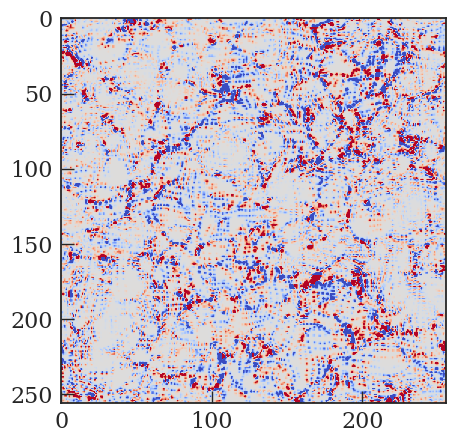

In [345]:
from matplotlib.colors import LogNorm
rho0 = mesh_rho0.paint(mode='real').value
rho2 = mesh_rho2.paint(mode='real').value

delta_dot_fd = (rho2 - rho0) / (t2 - t0) # in unit of Gyr^-1

fig, ax = plt.subplots(figsize=(5,5),ncols=1,nrows=1, sharex=True, sharey=True)

ax.imshow(delta_dot_fd[:,:,30],vmin=-0.5, vmax=0.5, cmap='coolwarm')

### compute delta_dot: continuity equation

In [160]:
import numpy as np
from numpy.fft import fftn, ifftn, fftfreq

In [85]:
# Unit conversion
h = cosmo.h  # set to your cosmology
MPC_IN_KM = 3.085677581491367e19
Gyr_IN_S = 1e9 * 365.25*24*3600
# conversion factor: (km/s)/(Mpc/h) -> Gyr^-1
conv_to_Gyrinv = h * Gyr_IN_S / MPC_IN_KM

# if your velocities are physical peculiar velocities V_phys (km/s):
# deltadot_Gyrinv = - (1.0 / a) * div_v * conv_to_Gyrinv

In [86]:
from pmesh.pm import RealField, ComplexField, ParticleMesh

In [99]:
def d_delta_dt_real(mesh_v1, mesh_v2, mesh_v3, z, cosmo):
    """
    Compute d(delta)/dt in 1/Gyr from velocity component meshes in km/s,
    return in real space.

    Parameters
    ----------
    mesh_v1, mesh_v2, mesh_v3 : Mesh
        Velocity components (km/s) in x, y, z directions.
    z : float
        Redshift.
    cosmo : nbodykit.cosmology.Cosmology
        Cosmology object (must support H(z) and scale_factor).

    Returns
    -------
    d_delta_dt_real : Mesh
        Time derivative of density contrast in 1/Gyr, in real space.
    """

    a = 1.0 / (1.0 + z)  # scale factor

    # Convert km/s per (Mpc/h) → 1/Gyr
    kmps_to_mpchGyr = (1.0 / cosmo.h) * 1.0227121650537077e-3
    # Fourier-space derivatives
    def div_filter(dir, order=1):
        if order == 0:
            def kernel(k, v):
                # clear the nyquist to ensure field is real
                mask = v.i[dir] != v.Nmesh[dir] // 2
                return v * (1j * k[dir]) * mask
        if order == 1:
            def kernel(k, v):
                cellsize = (v.BoxSize[dir] / v.Nmesh[dir])
                w = k[dir] * cellsize
    
                a = 1 / (6.0 * cellsize) * (8 * numpy.sin(w) - numpy.sin(2 * w))
                # a is already zero at the nyquist to ensure field is real
                return v * (1j * a)
        return kernel

    # Fourier-space derivatives
    #dv1_dx = mesh_v1.apply(div_filter(0), mode='complex', kind='wavenumber')
    #dv2_dy = mesh_v2.apply(div_filter(1), mode='complex', kind='wavenumber')
    #dv3_dz = mesh_v3.apply(div_filter(2), mode='complex', kind='wavenumber')
    dv1k = mesh_v1.to_field(mode='real').r2c()
    dv2k = mesh_v2.to_field(mode='real').r2c()
    dv3k = mesh_v3.to_field(mode='real').r2c()


    Nx, Ny, Nz_half = dv1k.Nmesh[0], dv1k.Nmesh[1], dv1k.Nmesh[2] // 2 + 1
    print(Nx, Ny, Nz_half)

    # 2/3 cutoff in each direction
    kx_cut = (Nx // 2) * 2 // 3
    ky_cut = (Ny // 2) * 2 // 3
    kz_cut = (Nz_half - 1) * 2 // 3  # careful with half spectrum
    
    # Get index arrays (broadcasted shapes)
    ix = dv1k.i[0]   # shape (Nx, 1, 1)
    iy = dv1k.i[1]   # shape (1, Ny, 1)
    iz = dv1k.i[2]   # shape (1, 1, Nz_half)
    
    # Wrap negative frequencies properly
    ix = np.where(ix > Nx//2, ix - Nx, ix)
    iy = np.where(iy > Ny//2, iy - Ny, iy)
    # iz doesn't need wrapping in r2c
    
    # Build mask with broadcasting
    mask = (np.abs(ix) <= kx_cut) & (np.abs(iy) <= ky_cut) & (np.abs(iz) <= kz_cut)
    
    # Apply filter
    dv1k[~mask] = 0
    dv2k[~mask] = 0
    dv3k[~mask] = 0

    dv1k_new = dv1k.apply(div_filter(0))
    dv2k_new = dv2k.apply(div_filter(1))
    dv3k_new = dv3k.apply(div_filter(2))

    # Divergence in km/s per (Mpc/h)
    theta_k_kmps = dv1k_new + dv2k_new + dv3k_new

    # Convert to 1/Gyr and apply continuity equation
    theta_k_1Gyr = theta_k_kmps * kmps_to_mpchGyr
    d_delta_dt_k = -(1.0 / a) * theta_k_1Gyr

    # Transform to real space
    return d_delta_dt_k.c2r()

In [117]:
def d_delta_dt_real_taper(mesh_v1, mesh_v2, mesh_v3, z, cosmo, taper_frac=2/3):
    """
    Compute d(delta)/dt in 1/Gyr from velocity component meshes with tapering in k-space.
    """
    import numpy as np

    a = 1.0 / (1.0 + z)
    kmps_to_mpchGyr = (1.0 / cosmo.h) * 1.0227121650537077e-3

    # Fourier space fields
    dv1k = mesh_v1.to_field(mode='real').r2c()
    dv2k = mesh_v2.to_field(mode='real').r2c()
    dv3k = mesh_v3.to_field(mode='real').r2c()

    Nx, Ny, Nz_half = dv1k.shape  # should be (128, 128, 65)

    kx = np.fft.fftfreq(Nx) * Nx
    ky = np.fft.fftfreq(Ny) * Ny
    kz = np.fft.rfftfreq(Nz_half*2) * (Nz_half*2)  # because rfft cuts in half
    
    # Example cosine taper
    taper_frac = 2/3  # fraction of box to keep before taper
    kx_cut = int(taper_frac * (Nx//2))
    ky_cut = int(taper_frac * (Ny//2))
    kz_cut = int(taper_frac * (Nz_half))
    
    tx = np.ones(Nx)
    tx[kx_cut:] = 0
    ty = np.ones(Ny)
    ty[ky_cut:] = 0
    tz = np.ones(Nz_half)
    tz[kz_cut:] = 0
    
    # Build full 3D taper (no extra dims)
    taper = tx[:, None, None] * ty[None, :, None] * tz[None, None, :]
    
    # Now apply
    dv1k.value *= taper
    dv2k.value *= taper
    dv3k.value *= taper

    # Divergence kernel
    def div_filter(dir):
        def kernel(k, v):
            mask = v.i[dir] != v.Nmesh[dir] // 2
            return v * (1j * k[dir]) * mask
        return kernel

    dv1k_new = dv1k.apply(div_filter(0))
    dv2k_new = dv2k.apply(div_filter(1))
    dv3k_new = dv3k.apply(div_filter(2))

    theta_k_kmps = dv1k_new + dv2k_new + dv3k_new
    theta_k_1Gyr = theta_k_kmps * kmps_to_mpchGyr
    d_delta_dt_k = -(1.0 / a) * theta_k_1Gyr

    return d_delta_dt_k.c2r()

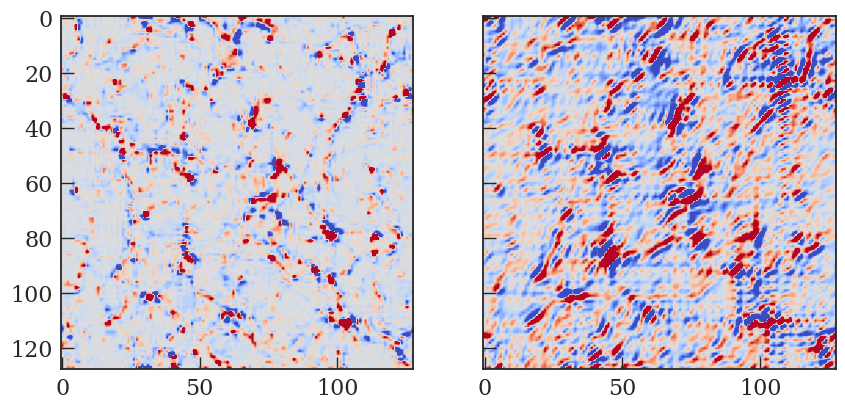

In [119]:
vx1 = mesh_vx1.paint(mode="real").value
vy1 = mesh_vy1.paint(mode="real").value
vz1 = mesh_vz1.paint(mode="real").value

#delta_dot_ct = d_delta_dt_real_numpy(vx1, vy1, vz1, z=z1, cosmo=cosmo, boxsize=400)
delta_dot_ct = d_delta_dt_real_taper(mesh_vx1, mesh_vy1, mesh_vz1, z=z1, cosmo=cosmo)
# print(mesh_vx1.attrs)



fig, ax = plt.subplots(figsize=(10,5),ncols=2,nrows=1, sharex=True, sharey=True)

ax[0].imshow(delta_dot_fd[:,:,30] / np.std(delta_dot_fd),vmin=-1, vmax=1, cmap='coolwarm')


ax[1].imshow(delta_dot_ct[:,:,30] / np.std(delta_dot_ct),vmin=-1, vmax=1, cmap='coolwarm')

In [102]:
idx = np.fft.fftfreq(4)
print(idx)

[ 0.    0.25 -0.5  -0.25]


In [103]:
from nbodykit.lab import *
# inititalize the mesh
delta_dot_fd2 = downsize(delta_dot_fd[:], factor=1)
delta_dot_ct2 = downsize(delta_dot_ct[:], factor=1)


print(delta_dot_ct2.shape)

mesh1 = ArrayMesh(delta_dot_fd2, BoxSize=400.0)
mesh2 = ArrayMesh(delta_dot_ct2, BoxSize=400.0)

delta = mesh_rho1.paint(mode='real').value - 1
delta2 = downsize(delta, factor=1)
print(delta2.shape)
meshd = ArrayMesh(delta2, BoxSize=400.0)

print(meshd.attrs)
print(mesh1.attrs)

(128, 128, 128)
(128, 128, 128)
{'BoxSize': array([400., 400., 400.]), 'Nmesh': array([128, 128, 128])}
{'BoxSize': array([400., 400., 400.]), 'Nmesh': array([128, 128, 128])}


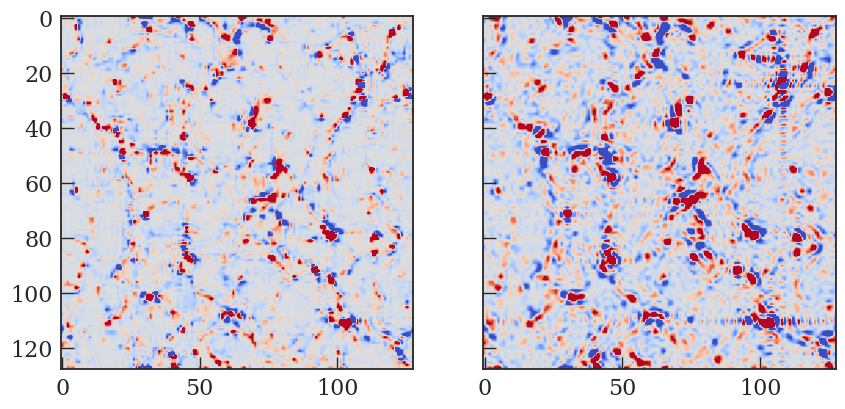

In [104]:
fig, ax = plt.subplots(figsize=(10,5),ncols=2,nrows=1, sharex=True, sharey=True)

ax[0].imshow(delta_dot_fd2[:,:,30] / np.std(delta_dot_fd2),vmin=-1, vmax=1, cmap='coolwarm')


ax[1].imshow(delta_dot_ct2[:,:,30] / np.std(delta_dot_ct2),vmin=-1, vmax=1, cmap='coolwarm')

In [105]:
def compute_power(mesh):
    rr = FFTPower(mesh,mode='1d')
    Pk = rr.power
    ps = Pk['power'].real - Pk.attrs['shotnoise']
    k0, Pk = Pk['k'], ps * Pk['k'] * Pk['k'] * Pk['k'] / (2 * np.pi * np.pi)
    return k0, Pk, ps

def compute_cross(mesh1, mesh2):
    k0_1, Pk_1, ps1 = compute_power(mesh1)
    k0_2, Pk_2, ps2 = compute_power(mesh2)
    
    rr = FFTPower(mesh1,second = mesh2, mode='1d')
    Pk = rr.power
    ps = Pk['power'].real - Pk.attrs['shotnoise']

    eta = ps / np.sqrt(ps1 * ps2)
    return k0_1, ps1, ps2, eta

/home/nianyic/.conda/envs/nbodykit-env/lib/python3.7/site-packages/ipykernel_launcher.py:16: RuntimeWarning: invalid value encountered in true_divide
  


[None]

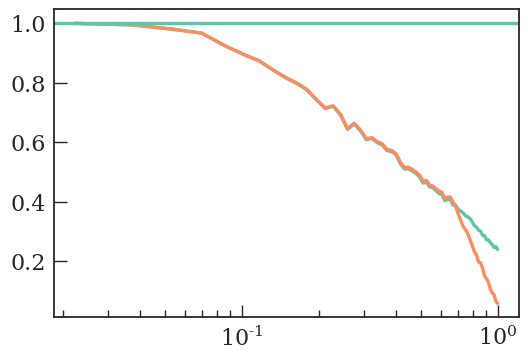

In [106]:
k0, ps1, ps2, eta1 = compute_cross(meshd, mesh1)

k0, ps1, ps2, eta2 = compute_cross(meshd, mesh2)

fig, ax = plt.subplots(1, 1, figsize=(6, 4))
ax.plot(k0, np.abs(eta1))
ax.plot(k0, np.abs(eta2))
ax.axhline(1)

ax.set(xscale="log")

/home/nianyic/.conda/envs/nbodykit-env/lib/python3.7/site-packages/ipykernel_launcher.py:16: RuntimeWarning: invalid value encountered in true_divide
  


[(0.95, 1.02)]

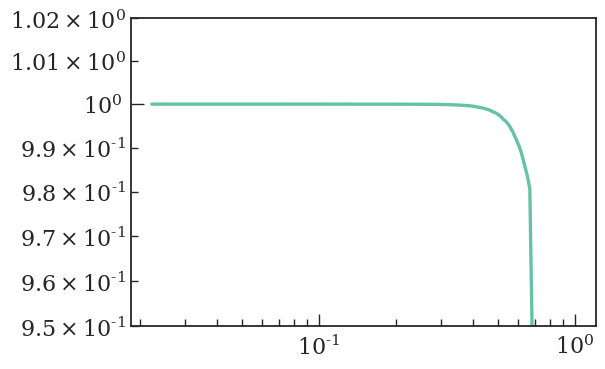

In [107]:
k0, ps1, ps2, eta = compute_cross(mesh1, mesh2)

fig, ax = plt.subplots(1, 1, figsize=(6, 4))
ax.plot(k0, np.abs(eta))
#ax.plot(k0, ps1)
#ax.plot(k0, ps2)
ax.set(xscale="log", yscale="log")
ax.set(ylim=[0.95, 1.02])

[None, None]

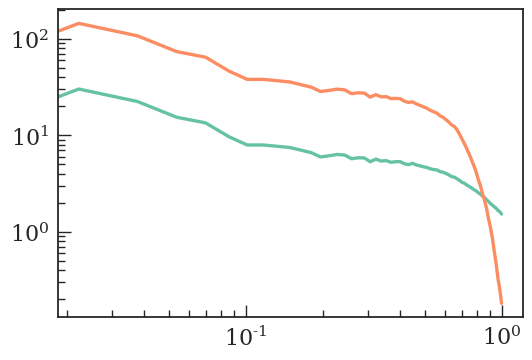

In [108]:

fig, ax = plt.subplots(1, 1, figsize=(6, 4))

ax.plot(k0, ps1)
ax.plot(k0, ps2)
ax.set(xscale="log", yscale="log")
# ax.set(ylim=[0.97, 1.02])

### numpy fft

In [59]:
def d_delta_dt_real_numpy(mesh_v1, mesh_v2, mesh_v3, z, cosmo, boxsize):
    """
    Compute d(delta)/dt in 1/Gyr from velocity component grids in km/s
    using NumPy FFTs, return in real space.

    Parameters
    ----------
    mesh_v1, mesh_v2, mesh_v3 : ndarray
        Velocity components (km/s) in x, y, z directions (real space).
        Must have shape (N, N, N) and be on the same grid.
    z : float
        Redshift.
    cosmo : nbodykit.cosmology.Cosmology
        Cosmology object (must support H(z) and scale_factor).

    Returns
    -------
    d_delta_dt : ndarray
        Time derivative of density contrast in 1/Gyr, real-space array.
    """
    # ---- Scale factor
    a = 1.0 / (1.0 + z)

    # ---- Unit conversion: km/s → Mpc/h per Gyr
    kmps_to_mpchGyr = (1.0 / cosmo.h) * 1.0227121650537077e-3

    # ---- FFT grid info
    N = mesh_v1.shape[0]
    kfreq = np.fft.fftfreq(N, d=boxsize / N) * 2.0 * np.pi  # k in h/Mpc

    kx, ky, kz = np.meshgrid(kfreq, kfreq, kfreq, indexing='ij')

    # ---- FFT velocities
    v1k = np.fft.fftn(mesh_v1)
    v2k = np.fft.fftn(mesh_v2)
    v3k = np.fft.fftn(mesh_v3)

    # ---- Divergence in Fourier space: i*k_x*v_x + i*k_y*v_y + i*k_z*v_z
    theta_k_kmps = 1j * (kx * v1k + ky * v2k + kz * v3k)

    # ---- Convert to 1/Gyr
    theta_k_1Gyr = theta_k_kmps * kmps_to_mpchGyr

    # ---- Continuity equation: dδ/dt = -(1/a) * θ
    d_delta_dt_k = -(1.0 / a) * theta_k_1Gyr

    # ---- Back to real space (result should be real)
    d_delta_dt_real = np.fft.ifftn(d_delta_dt_k).real

    return d_delta_dt_real

In [139]:
def d_delta_dt_real_numpy_taper(vx, vy, vz, z, cosmo, boxsize, taper_frac=2/3):
    """
    Compute d(delta)/dt from velocity fields using the continuity equation,
    with an optional Fourier-space taper to avoid aliasing.

    Parameters
    ----------
    vx, vy, vz : ndarray
        Velocity components in km/s (real space) on a cubic grid, shape (N, N, N)
    z : float
        Redshift
    cosmo : object
        Cosmology with `H(z)` in km/s/Mpc
    boxsize : float
        Box size in Mpc/h
    taper_frac : float
        Fraction of Nyquist frequency to keep before tapering (default 2/3)

    Returns
    -------
    delta_dot : ndarray
        Real-space d(delta)/dt field
    """

    N = vx.shape[0]
    assert vx.shape == (N, N, N), "Velocity grids must be cubic"

    # Compute k-vectors
    kx = np.fft.fftfreq(N, d=boxsize/N) * 2*np.pi
    ky = np.fft.fftfreq(N, d=boxsize/N) * 2*np.pi
    kz = np.fft.rfftfreq(N, d=boxsize/N) * 2*np.pi

    kx3, ky3, kz3 = np.meshgrid(kx, ky, kz, indexing='ij')

    # FFT of velocity components
    dv1k = np.fft.rfftn(vx)
    dv2k = np.fft.rfftn(vy)
    dv3k = np.fft.rfftn(vz)

    # Fourier-space divergence
    div_v_k = 1j*(kx3 * dv1k + ky3 * dv2k + kz3 * dv3k)

    # Apply smooth taper to suppress high-k modes (cosine roll-off)
    k_mag = np.sqrt(kx3**2 + ky3**2 + kz3**2)
    k_nyquist = np.pi * N / boxsize  # Nyquist in h/Mpc
    k_cut = taper_frac * k_nyquist
    taper = 0.5 * (1 + np.cos(np.pi * (k_mag - k_cut) / (k_nyquist - k_cut)))
    taper[k_mag <= k_cut] = 1
    taper[k_mag >= k_nyquist] = 0

    div_v_k *= taper

    # Back to real space
    div_v_real = np.fft.irfftn(div_v_k, s=(N, N, N))

    # Convert velocities from km/s to Mpc/h per unit time
    a = 1.0 / (1 + z)
    Hz = cosmo.H(z)  # km/s/Mpc
    delta_dot = - (1.0 / a) * div_v_real / (boxsize/N) / Hz

    return delta_dot

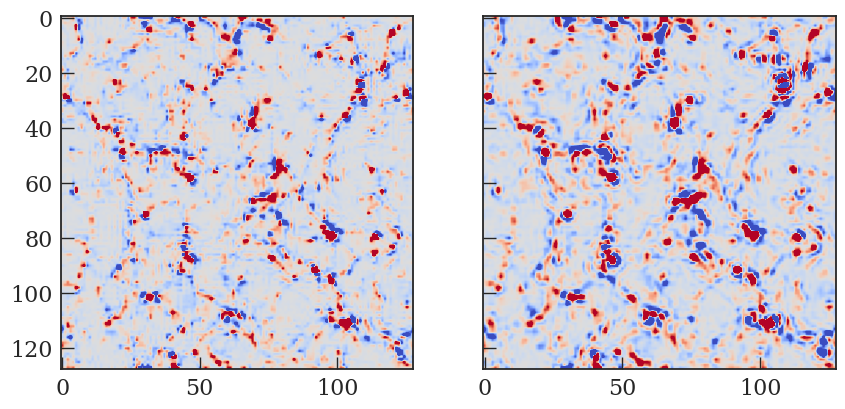

In [140]:
vx1 = mesh_vx1.paint(mode="real").value
vy1 = mesh_vy1.paint(mode="real").value
vz1 = mesh_vz1.paint(mode="real").value

#delta_dot_ct = d_delta_dt_real_numpy(vx1, vy1, vz1, z=z1, cosmo=cosmo, boxsize=400)
delta_dot_ct = d_delta_dt_real_numpy_taper(vx1, vy1, vz1, z=z1, cosmo=cosmo, boxsize=400)
# print(mesh_vx1.attrs)



fig, ax = plt.subplots(figsize=(10,5),ncols=2,nrows=1, sharex=True, sharey=True)

ax[0].imshow(delta_dot_fd[:,:,30] / np.std(delta_dot_fd),vmin=-1, vmax=1, cmap='coolwarm')


ax[1].imshow(delta_dot_ct[:,:,30] / np.std(delta_dot_ct),vmin=-1, vmax=1, cmap='coolwarm')

(128, 128, 128)
(128, 128, 128)
{'BoxSize': array([400., 400., 400.]), 'Nmesh': array([128, 128, 128])}
{'BoxSize': array([400., 400., 400.]), 'Nmesh': array([128, 128, 128])}


In [ ]:
from nbodykit.lab import *
# inititalize the mesh
delta_dot_fd2 = downsize(delta_dot_fd[:], factor=1)
delta_dot_ct2 = downsize(delta_dot_ct[:], factor=1)


print(delta_dot_ct2.shape)

mesh1 = ArrayMesh(delta_dot_fd2, BoxSize=400.0)
mesh2 = ArrayMesh(delta_dot_ct2, BoxSize=400.0)

delta = mesh_rho1.paint(mode='real').value - 1
delta2 = downsize(delta, factor=1)
print(delta2.shape)
meshd = ArrayMesh(delta2, BoxSize=400.0)

print(meshd.attrs)
print(mesh1.attrs)

/home/nianyic/.conda/envs/nbodykit-env/lib/python3.7/site-packages/ipykernel_launcher.py:16: RuntimeWarning: invalid value encountered in true_divide
  


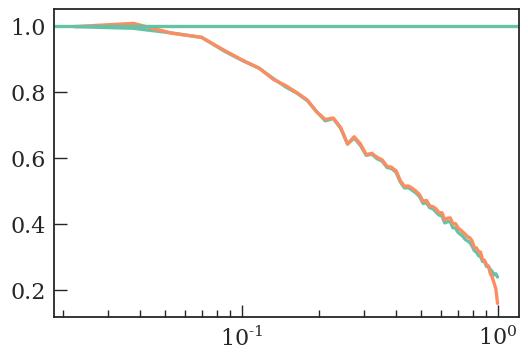

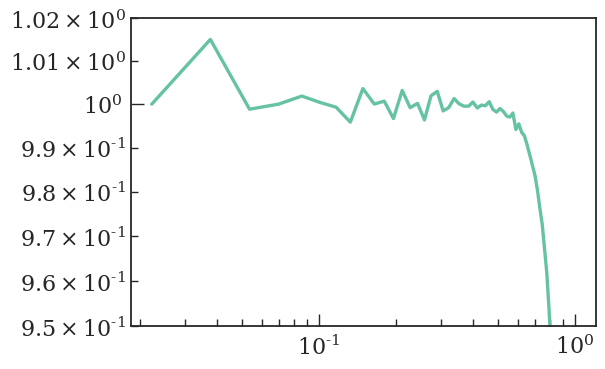

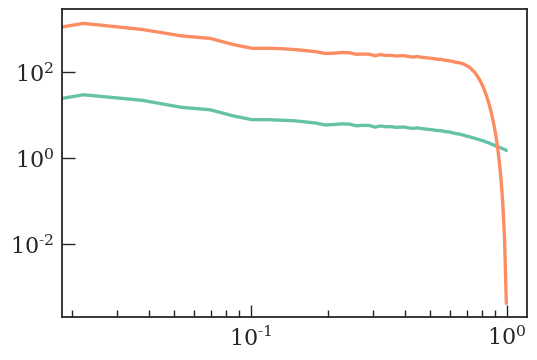

In [147]:
k0, ps1, ps2, eta1 = compute_cross(meshd, mesh1)

k0, ps1, ps2, eta2 = compute_cross(meshd, mesh2)

fig, ax = plt.subplots(1, 1, figsize=(6, 4))
ax.plot(k0, np.abs(eta1))
ax.plot(k0, np.abs(eta2))
ax.axhline(1)

ax.set(xscale="log")
plt.show()


k0, ps1, ps2, eta = compute_cross(mesh1, mesh2)

fig, ax = plt.subplots(1, 1, figsize=(6, 4))
ax.plot(k0, np.abs(eta))
#ax.plot(k0, ps1)
#ax.plot(k0, ps2)
ax.set(xscale="log", yscale="log")
ax.set(ylim=[0.95, 1.02])
plt.show()


fig, ax = plt.subplots(1, 1, figsize=(6, 4))

ax.plot(k0, ps1)
ax.plot(k0, ps2)
ax.set(xscale="log", yscale="log")
# ax.set(ylim=[0.97, 1.02])
plt.show()

[None, None]

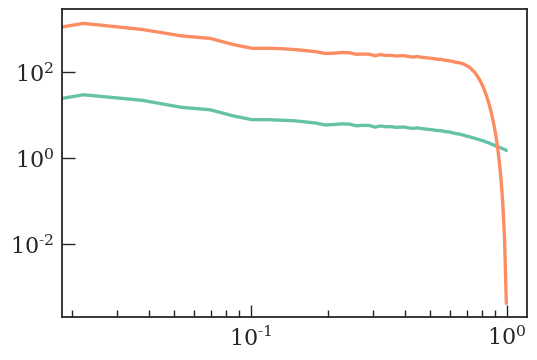

### real space

In [354]:

def wrapping(v1, N):
    v1_pad = np.zeros((N+2, N+2, N+2))
    v1_pad[1:-1, 1:-1, 1:-1] = v1[:]
    
    v1_pad[0, 1:-1, 1:-1] = v1[-1, :, :]
    v1_pad[-1, 1:-1, 1:-1] = v1[0, :, :]
    v1_pad[1:-1, 0, 1:-1] = v1[:, -1, :]
    v1_pad[1:-1, -1, 1:-1] = v1[:, 0, :]
    v1_pad[1:-1, 1:-1, 0] = v1[:, :, -1]
    v1_pad[1:-1, 1:-1, -1] = v1[:, :, 0]

    return v1_pad

def d_delta_dt_realspace(v1, v2, v3, z, cosmo, boxsize):
    """
    Compute d(delta)/dt in 1/Gyr from velocity component grids in km/s
    in real space using finite differences.

    Parameters
    ----------
    mesh_v1, mesh_v2, mesh_v3 : ndarray
        Velocity components (km/s) in x, y, z directions (real space).
        Shape (N, N, N), same grid.
    z : float
        Redshift.
    cosmo : nbodykit.cosmology.Cosmology
        Cosmology object (must support H(z) and scale_factor).
    boxsize : float
        Size of the box in Mpc/h.

    Returns
    -------
    d_delta_dt : ndarray
        Time derivative of density contrast in 1/Gyr, real-space array.
    """

    # ---- Scale factor
    a = 1.0 / (1.0 + z)

    # ---- Unit conversion: km/s → Mpc/h per Gyr
    v_kmps = 1.0 * units.km / units.s
    v_mpc_per_s = v_kmps.to(units.Mpc / units.s)
    v_mpc_per_Gyr = v_mpc_per_s.to(units.Mpc / units.Gyr)
    kmps_to_mpchGyr = v_mpc_per_Gyr / cosmo.h

    # ---- Grid spacing in Mpc/h
    N = v1.shape[0]
    dx = boxsize / N

    # ---- Convert velocities to Mpc/h per Gyr
    v1_pad = wrapping(v1, N) 
    v2_pad = wrapping(v2, N)
    v3_pad = wrapping(v3, N)
    # ---- Compute divergence in real space
    dv1_dx = np.gradient(v1_pad * kmps_to_mpchGyr, dx, axis=0)[1:-1, 1:-1, 1:-1]
    dv2_dy = np.gradient(v2_pad * kmps_to_mpchGyr, dx, axis=1)[1:-1, 1:-1, 1:-1]
    dv3_dz = np.gradient(v3_pad * kmps_to_mpchGyr, dx, axis=2)[1:-1, 1:-1, 1:-1]

    divergence = dv1_dx + dv2_dy + dv3_dz  # in 1/Gyr

    # ---- Continuity equation
    d_delta_dt_real = -(1.0 / a**2) * divergence

    return d_delta_dt_real

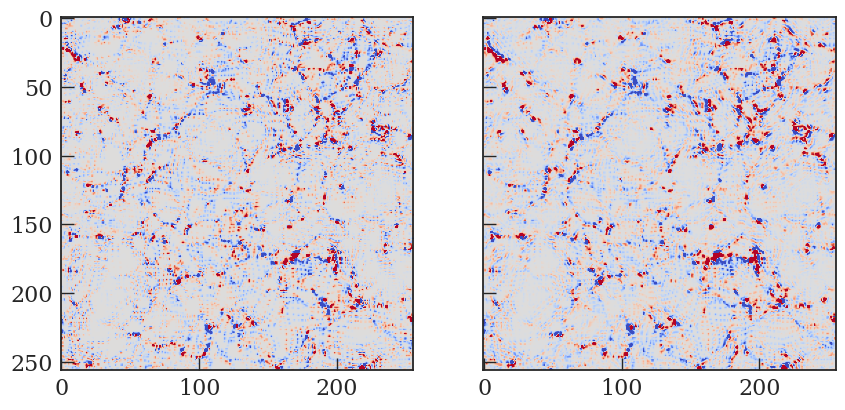

In [355]:
vx1 = mesh_vx1.paint(mode="real").value
vy1 = mesh_vy1.paint(mode="real").value
vz1 = mesh_vz1.paint(mode="real").value

#delta_dot_ct = d_delta_dt_real_numpy(vx1, vy1, vz1, z=z1, cosmo=cosmo, boxsize=400)
delta_dot_ct = d_delta_dt_realspace(vx1, vy1, vz1, z=z1, cosmo=cosmo, boxsize=400)
# print(mesh_vx1.attrs)



fig, ax = plt.subplots(figsize=(10,5),ncols=2,nrows=1, sharex=True, sharey=True)

ax[0].imshow(delta_dot_fd[:,:,30] / np.std(delta_dot_fd),vmin=-1, vmax=1, cmap='coolwarm')
ax[1].imshow(delta_dot_ct[:,:,30] / np.std(delta_dot_ct),vmin=-1, vmax=1, cmap='coolwarm')

In [356]:
0.9968939423561096 / 1.3057910203933716

0.7634406476893935

0.9927908182144165 1 / Gyr
1.289505222873035 Mpc / Gyr
2.837623469531536e-10 1 / Gyr
1.1926223897340549e-18 Mpc / Gyr
<class 'astropy.units.quantity.Quantity'>


[None]

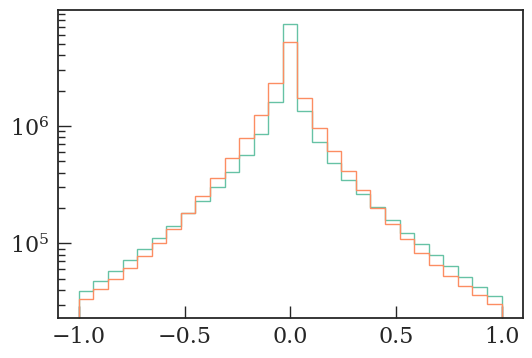

In [357]:
print(delta_dot_fd.std())
print(delta_dot_ct.std())

print(delta_dot_fd.mean())
print(delta_dot_ct.mean())

print(type(delta_dot_fd))

fig, ax = plt.subplots(1, 1, figsize=(6, 4))
ax.hist(delta_dot_fd.value.flatten() / delta_dot_fd.value.std(), bins=np.linspace(-1, 1, 30), histtype="step")
ax.hist(delta_dot_ct.value.flatten() / delta_dot_ct.value.std(), bins=np.linspace(-1, 1, 30), histtype="step")

ax.set(yscale="log")


(256, 256, 256)
(256, 256, 256)
{'BoxSize': array([400., 400., 400.]), 'Nmesh': array([256, 256, 256])}
{'BoxSize': array([400., 400., 400.]), 'Nmesh': array([256, 256, 256])}


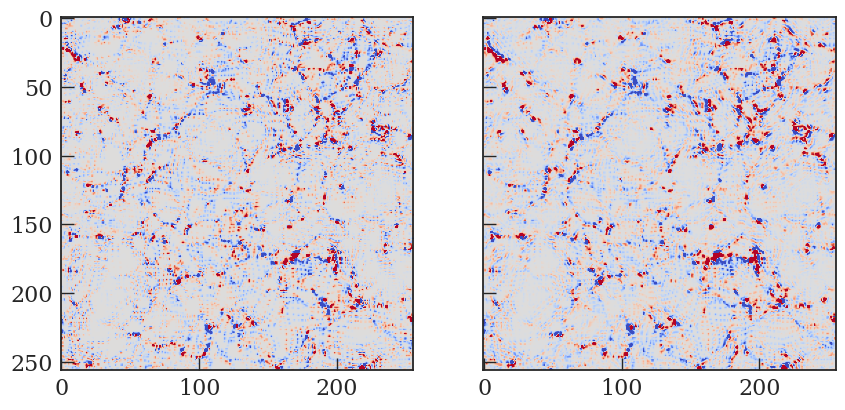

In [358]:
from nbodykit.lab import *
# inititalize the mesh
delta_dot_fd2 = downsize(delta_dot_fd[:], factor=1)
delta_dot_ct2 = downsize(delta_dot_ct[:], factor=1)


print(delta_dot_ct2.shape)

mesh1 = ArrayMesh(delta_dot_fd2, BoxSize=400.0)
mesh2 = ArrayMesh(delta_dot_ct2, BoxSize=400.0)

delta = mesh_rho1.paint(mode='real').value - 1
delta2 = downsize(delta, factor=1)
print(delta2.shape)
meshd = ArrayMesh(delta2, BoxSize=400.0)

print(meshd.attrs)
print(mesh1.attrs)

fig, ax = plt.subplots(figsize=(10,5),ncols=2,nrows=1, sharex=True, sharey=True)

ax[0].imshow(delta_dot_fd2[:,:,30] / np.std(delta_dot_fd2),vmin=-1, vmax=1, cmap='coolwarm')


ax[1].imshow(delta_dot_ct2[:,:,30] / np.std(delta_dot_ct2),vmin=-1, vmax=1, cmap='coolwarm')

0.9927908182144165 1 / Gyr
1.289505222873035 Mpc / Gyr
2.837623469531536e-10 1 / Gyr
1.1926223897340549e-18 Mpc / Gyr
<class 'astropy.units.quantity.Quantity'>


[None]

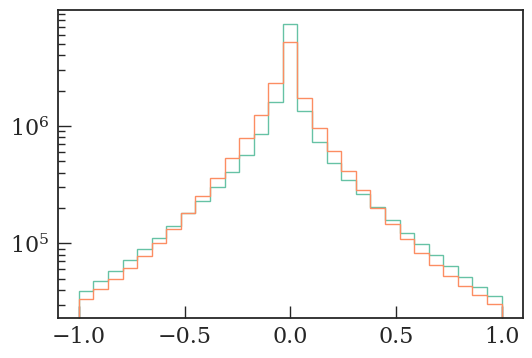

In [359]:
print(delta_dot_fd2.std())
print(delta_dot_ct2.std())

print(delta_dot_fd2.mean())
print(delta_dot_ct2.mean())

print(type(delta_dot_fd))

fig, ax = plt.subplots(1, 1, figsize=(6, 4))
ax.hist(delta_dot_fd2.value.flatten() / delta_dot_fd2.value.std(), bins=np.linspace(-1, 1, 30), histtype="step")
ax.hist(delta_dot_ct2.value.flatten() / delta_dot_ct2.value.std(), bins=np.linspace(-1, 1, 30), histtype="step")

ax.set(yscale="log")


/home/nianyic/.conda/envs/nbodykit-env/lib/python3.7/site-packages/ipykernel_launcher.py:16: RuntimeWarning: invalid value encountered in true_divide
  


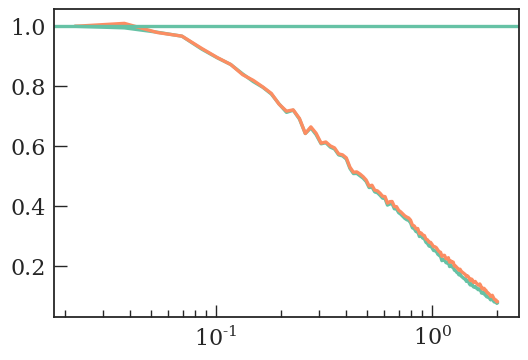

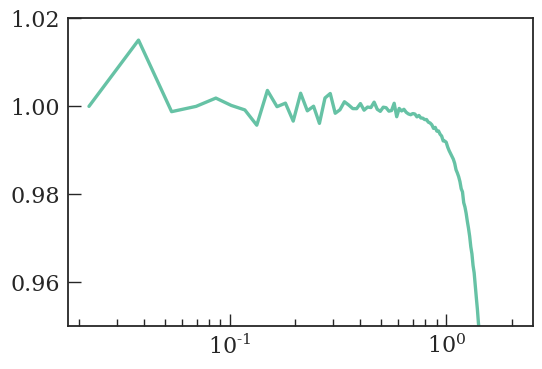

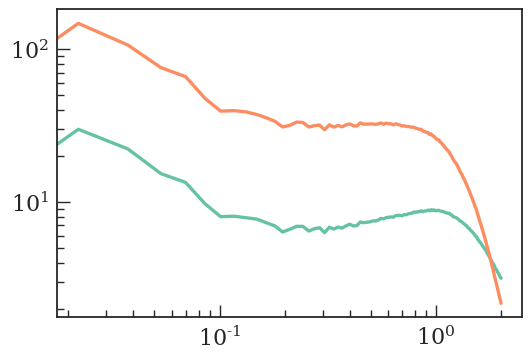

In [360]:
k0, ps1, ps2, eta1 = compute_cross(meshd, mesh1)

k0, ps1, ps2, eta2 = compute_cross(meshd, mesh2)

fig, ax = plt.subplots(1, 1, figsize=(6, 4))
ax.plot(k0, np.abs(eta1))
ax.plot(k0, np.abs(eta2))
ax.axhline(1)

ax.set(xscale="log")
plt.show()


k0, ps1, ps2, eta = compute_cross(mesh1, mesh2)

fig, ax = plt.subplots(1, 1, figsize=(6, 4))
ax.plot(k0, np.abs(eta))
#ax.plot(k0, ps1)
#ax.plot(k0, ps2)
ax.set(xscale="log")
ax.set(ylim=[0.95, 1.02])
plt.show()


fig, ax = plt.subplots(1, 1, figsize=(6, 4))

ax.plot(k0, ps1)
ax.plot(k0, ps2)


ax.set(xscale="log", yscale="log")
# ax.set(ylim=[0.97, 1.02])
plt.show()

### sph method

In [241]:
import numpy as np
from scipy.spatial import cKDTree

def cubic_spline_kernel_3d(r, h):
    """
    3D cubic spline SPH kernel and gradient for an array of displacement vectors r
    with adaptive smoothing lengths h per particle.

    Parameters
    ----------
    r : (N,3) ndarray
        Displacement vectors r = x_grid - x_particle
    h : (N,) ndarray
        Smoothing lengths for each neighbor

    Returns
    -------
    W : (N,) ndarray
        Kernel values
    gradW : (N,3) ndarray
        Kernel gradients
    """
    r_norm = np.linalg.norm(r, axis=1)
    q = r_norm / h
    W = np.zeros_like(q)
    gradW = np.zeros_like(r)

    for i in range(len(r)):
        if q[i] <= 0.5:
            W[i] = 8/(np.pi*h[i]**3) * (1 - 6*q[i]**2 + 6*q[i]**3)
            if r_norm[i] > 0:
                gradW[i] = 8/(np.pi*h[i]**3) * (-12*q[i] + 18*q[i]**2) * (r[i]/(r_norm[i]*h[i]))
        elif q[i] <= 1.0:
            W[i] = 8/(np.pi*h[i]**3) * 2*(1-q[i])**3
            if r_norm[i] > 0:
                gradW[i] = 8/(np.pi*h[i]**3) * (-6*(1-q[i])**2) * (r[i]/(r_norm[i]*h[i]))
        else:
            W[i] = 0.0
            gradW[i] = 0.0

    return W, gradW


def velocity_divergence_sph_grid(pos, vel, boxsize, Nmesh, N_neighbors=32):
    """
    Compute Eulerian grid velocity divergence using SPH cubic spline kernel.

    Parameters
    ----------
    pos : (N,3) ndarray
        Particle positions in Mpc/h
    vel : (N,3) ndarray
        Particle velocities in km/s (comoving)
    boxsize : float
        Simulation box size in Mpc/h
    Nmesh : int
        Grid resolution per dimension
    N_neighbors : int
        Number of nearest neighbors to determine adaptive smoothing length

    Returns
    -------
    div_grid : (Nmesh,Nmesh,Nmesh) ndarray
        Eulerian velocity divergence on grid
    """

    dx = boxsize / Nmesh
    grid_coords = (np.arange(Nmesh) + 0.5) * dx  # cell-centered
    X, Y, Z = np.meshgrid(grid_coords, grid_coords, grid_coords, indexing='ij')
    grid_points = np.column_stack([X.ravel(), Y.ravel(), Z.ravel()])
    Ngrid = grid_points.shape[0]

    div_grid = np.zeros(Ngrid)

    # KDTree for periodic box
    tree = cKDTree(pos, boxsize=boxsize)

    # Determine adaptive h for each particle from nearest neighbors
    dists, _ = tree.query(pos, k=N_neighbors)
    h_particles = dists.max(axis=1) + 1e-10  # add small epsilon

    # Loop over grid points
    for i in range(Ngrid):
        gp = grid_points[i]
        # find particles within max smoothing length
        idxs = tree.query_ball_point(gp, r=np.max(h_particles))
        if len(idxs) == 0:
            continue
        neighbors_pos = pos[idxs]
        neighbors_vel = vel[idxs]
        neighbors_h = h_particles[idxs]

        # compute displacement vectors with periodic BC
        dx_vec = neighbors_pos - gp
        dx_vec = dx_vec - boxsize * np.round(dx_vec / boxsize)

        # compute kernel gradients
        _, gradW = cubic_spline_kernel_3d(dx_vec, neighbors_h)

        # compute weighted grid velocity for outer product
        W = np.ones_like(neighbors_h)  # optional: can weight by kernel if needed
        v_grid = np.sum(neighbors_vel * W[:,None], axis=0) / np.sum(W)

        # velocity gradient tensor and divergence
        dv = neighbors_vel - v_grid
        grad_v = np.einsum('ij,ik->jk', dv, gradW)
        div_grid[i] = np.trace(grad_v)
        
    a = 1/(1+z)
    kmps_to_mpchGyr = (1.0 / cosmo.h) * 1.0227121650537077e-3
    div_grid_1Gyr = -div_grid / a * kmps_to_mpchGyr

    return div_grid_1Gyr.reshape((Nmesh, Nmesh, Nmesh))

In [242]:
snap1, snap2 = 2, 3
z1, z2 = zlist[snap1], zlist[snap2]
a1, a2 = alist[snap1], alist[snap2]
t1, t2 = tlist[snap1], tlist[snap2]


sdir1 = snapfiles[snap1]
hf = h5py.File(sdir1)
pos1 = hf["PartType1/Coordinates"][:]
vel1 = hf["PartType1/Velocities"][:] / np.sqrt(a1)

In [243]:
div_grid_sph = velocity_divergence_sph_grid(pos=pos1, vel=vel1, boxsize=400, Nmesh=64, N_neighbors=32)

NameError: name 'z' is not defined

In [ ]:
fig, ax = plt.subplots(figsize=(10,5),ncols=2,nrows=1, sharex=True, sharey=True)

ax[0].imshow(delta_dot_fd[:,:,30] / np.std(delta_dot_fd),vmin=-1, vmax=1, cmap='coolwarm')
ax[1].imshow(delta_dot_ct[:,:,30] / np.std(delta_dot_ct),vmin=-1, vmax=1, cmap='coolwarm')

In [ ]:
print(delta_dot_fd.std())
print(delta_dot_ct.std())


print(type(delta_dot_fd))

fig, ax = plt.subplots(1, 1, figsize=(6, 4))
ax.hist(delta_dot_fd.value.flatten(), bins=np.linspace(-1, 1, 30), histtype="step")
ax.hist(delta_dot_ct.value.flatten(), bins=np.linspace(-1, 1, 30), histtype="step")

ax.set(yscale="log")
